# Schbib et al. (1996): audited steady-state PFR benchmark

## Current result

This notebook runs a 1D isothermal plug-flow mass balance against all three Table 6 cases using two **separate** parameter sets: the original printed Table 8 and the later author-shared correction record. The original set reproduces the historical near-zero acetylene conversions. The correction set brings acetylene conversion within 1.5 percentage points, but neither source set reproduces the reported ethylene conversion within the 2-point engineering gate. Overall Table 6 reproduction is **BLOCKED**.

The correction is not verified as a journal erratum, and its linked PDF cannot currently be fetched from the author-shared page. Its text transcription is tested as a distinct candidate set, not promoted to formal corrected truth. The Figure 3 and 4 acetylene outlet values are close under an explicitly borrowed 1 g / 100 cm³(STP) min⁻¹ condition, but the paper uses a nonisothermal model III that this notebook does not claim to reproduce.

This is an AI-produced research artifact. It does not certify the kinetics for a different catalyst, including PdAg.

## Contents

1. Source records and parameter interpretations
2. Mass-coordinate PFR and source-set comparisons
3. One-factor diagnostics and coupled unit effects
4. Figure 1–4 reproduction gates
5. Stoichiometry, unit invariance, positivity, and solver checks
6. Reproducibility receipt and limitations


## Source records and verification status

### Original article

The archived article PDF at `research/literature/schbib_1996_front_end_acetylene_hydrogenation.pdf` was rendered and visually checked on PDF page 4 (printed p.1499: Tables 3, 4, 6 and reactor description), page 6 (printed p.1501: Eqs. 22, 24 and 25), page 7 (printed p.1502: Table 8 and its full rate law), and page 8 (printed p.1503: Figures 3 and 4 and accompanying text). `research/literature/schbib_1996_extracted_text.txt` and `schbib_1996_full_article.html` were used as findable reading aids. Source hashes and page-level transcription are recorded in the audit report and `research/evidence/transcriptions/schbib_1996_parameter_tables.md`.

### Author-shared correction record

The public ResearchGate full-text page says the correction content was uploaded by Noemi Susana Schbib on 2021-01-25 and its extracted article text appends a note that Table 8 contained erroneous values for the five adsorption constants. The note lists the values reproduced below. The page's PDF download link currently returns HTTP 404. Therefore the correction transcription was compared against the page's machine-readable text, **not checked visually against its document image**. The publisher article page identifies the 1996 article but no separately linked erratum was located in the checked ACS article/issue records; absence from those pages does not prove no erratum exists.

Sources: [ACS article record](https://pubs.acs.org/doi/abs/10.1021/ie950600k), [ResearchGate author-shared full-text page](https://www.researchgate.net/publication/231391687_Kinetics_of_Front-End_Acetylene_Hydrogenation_in_Ethylene_Production).

### Historical notebook and plots

The previous executed notebook is archived byte-for-byte as `schbib_1996_steady_state_historical.ipynb`. Its saved outputs and four same-named PNGs are historical artifacts; they are not rewritten by this notebook. A temporary copy of the old notebook was freshly executed before replacing this file. That run returned Table 6 acetylene conversions 0.8467%, 0.0099%, and 0.0018% for CO 150, 1400, and 5000 ppm, respectively, matching its stored outputs. Those values belong to the old simplified, adiabatic, per-gram implementation.


## Transcribed data: retain source versions separately

**Table 3, p.1499:** CH₄ 6.53 mol%, C₂H₂ 0.52%, C₂H₄ 43.99%, C₂H₆ 26.72%, H₂ 22.1%; CO is varied separately from 150 to 5000 ppm. Flow is 100 cm³(STP)/min; catalyst mass 1–3 g; pressure 1–35 atm; temperature 288–393 K. The listed hydrocarbon/H₂ fractions sum to 99.86% due to rounding; the code scales them to sum to (1-y_{CO}).

**Table 4, p.1499:** ICI 38-1, α-Al₂O₃, 0.04 wt% Pd, H/Pd dispersion 0.15, apparent density 1.61 g/cm³, real density 3.61 g/cm³, mean pore diameter 1000 Å, pore volume 0.338 cm³/g, and catalyst porosity 54.5%. The reported porosity is a catalyst property; it is not a measured packed-bed void fraction.

**Table 6, p.1499:** (P=16) atm and (SV=100) cm³(STP) gcat⁻¹ min⁻¹. With the Table 3 flow of 100 cm³(STP)/min, this fixes catalyst mass at 1 g. The cases are:

| CO (ppm) | T (K) | C₂H₂ conversion (%) | C₂H₄ conversion (%) |
|---:|---:|---:|---:|
| 150 | 341 | 98.31 | 10.45 |
| 1400 | 359 | 98.99 | 6.70 |
| 5000 | 393 | 98.62 | 6.08 |

Table 8 (printed p.1502) reports `log A_i`, (E) (kcal/gmol), and units. The later author-shared table is shown separately. The author's note retains the kA/kE log values but reports a kgcat rate basis and changes all five adsorption entries.

| Parameter | Printed `log A_i` | E (kcal/mol) | Printed basis / unit | Author-shared `log A_i` | Author-shared basis / unit |
|---|---:|---:|---|---:|---|
| k_A | 31.1 | 45.51 | gcat; m⁶/(s gcat kmol) | 31.1 | kgcat; m⁶/(s kgcat kmol) |
| k_E | 26.6 | 42.94 | gcat; m⁶/(s gcat kmol) | 26.6 | kgcat; m⁶/(s kgcat kmol) |
| K_H | 20.2 | 21.22 | m³/kmol | 17.2 | m³/kmol |
| K_CO | 13.6 | 9.95 | m³/kmol | 10.16 | m³/kmol |
| K_E | 0.26 | 0.005 | m³/kmol | -2.74 | m³/kmol |
| K_Et | -0.012 | 0.001 | m³/kmol | -3.012 | m³/kmol |
| K_A | -16 | 0.001 | m³/kmol | -19.0 | m³/kmol |

The source table labels the logarithm `log A_i` without printing a base. The implementation uses (log_{10}), the conventional interpretation for these tabulated kinetic pre-exponentials. This is an interpretation, not a visible subscript in the article. The values in the table are logarithms; (A=10^{log_{10}A}), not (A=log_{10}A).


## Equation and unit interpretation

The selected full Table 8 law on printed p.1502 is

\[
-r_A=\frac{k_A C_A C_H}{D^3},\qquad
-r_E=\frac{k_E C_E C_H}{D^3},\qquad
D=1+(K_H C_H)^{1/2}+K_A C_A+K_E C_E+K_{Et}C_{Et}+K_{CO}C_{CO}.
\]

The paper says (K_A,K_E,K_{Et}) have negligible effect and gives the reduced laws as Eqs. 24–25 on printed p.1501, dropping those three terms. Both equation forms are run against each source parameter set. The denominator exponent is 3. With concentrations in kmol/m³ and k in m⁶/(s·mass·kmol), each numerator has rate units kmol/(mass·s); every adsorption product is dimensionless.

For temperature dependence, the interpretation is (p(T)=10^{\log_{10} A}\exp[-E/(RT)]), converting kcal/mol with 4184 J/kcal. The article says positive tabulated adsorption energies imply (K_H) and (K_{CO}) increase with temperature (printed p.1501), consistent with this sign. Eq. 22 is a relative surface-to-bulk Arrhenius relation; it does not provide a separate absolute pre-exponential convention. The log base and absolute (A) convention are therefore recorded as interpretations.

The PFR is integrated in catalyst mass (W), avoiding a guessed packed-bed length or void fraction:

\[
\frac{d\mathbf F}{dW}=\boldsymbol\nu\mathbf r.
\]

Rates are canonicalized to kgcat for this state coordinate. The original printed kA/kE coefficients are per gram and are multiplied by (10^3) when converted to a per-kilogram rate basis (+3 in log₁₀ A). The author-shared set is already per kilogram and is left numerically unchanged. This 1000-fold difference is part of the source comparison, not silently reconciled. A separate mol/m³ implementation tests exact concentration-unit invariance.

Radau's implicit trial states can cross zero near reactant depletion. For rate evaluation only, negative trial concentrations are floored at zero; the integrated states and reported conversions are not clipped. Accepted trajectory flows are checked separately against a small numerical tolerance.

For reported C₂H₄ conversion, the primary comparison uses the species net disappearance (100(F_{E,0}-F_{E,out})/F_{E,0}). Since reaction 1 produces ethylene, a second diagnostic reports reaction-2 extent divided by inlet ethylene. Neither is clipped at 0 or 100%; a negative net value means net ethylene formation in the modeled outlet.


In [1]:
import math
import platform
import sys
from dataclasses import dataclass, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.integrate import solve_ivp

R_J_MOL_K = 8.314462618
R_PA_M3_KMOL_K = 8314.462618
R_PA_M3_MOL_K = 8.314462618
P_ATM_PA = 101325.0
T_STP_K = 273.15
P_STP_PA = 101325.0
SPECIES = ("CH4", "C2H2", "C2H4", "C2H6", "H2", "CO")
I = {name: ix for ix, name in enumerate(SPECIES)}

# Table 3 source values; CO is a separate measured feed addition.
FEED_TABLE3 = np.array([0.0653, 0.0052, 0.4399, 0.2672, 0.2210, 0.0])
# Each reaction column: C2H2 + H2 -> C2H4; C2H4 + H2 -> C2H6.
NU = np.array([[0, 0], [-1, 0], [1, -1], [0, 1], [-1, -1], [0, 0]], dtype=float)
# Rows C,H,O; columns in SPECIES order.
ELEMENTS = np.array([[1, 2, 2, 2, 0, 1], [4, 2, 4, 6, 2, 0], [0, 0, 0, 0, 0, 1]], dtype=float)

@dataclass(frozen=True)
class KineticSet:
    label: str
    source: str
    log_kA: float
    E_kA_kcal_mol: float
    log_kE: float
    E_kE_kcal_mol: float
    log_KH: float
    E_KH_kcal_mol: float
    log_KCO: float
    E_KCO_kcal_mol: float
    log_KE: float
    E_KE_kcal_mol: float
    log_KEt: float
    E_KEt_kcal_mol: float
    log_KA: float
    E_KA_kcal_mol: float
    rate_mass_basis: str

TABLE8_PRINTED = KineticSet(
    "Original printed Table 8", "printed_article_table_8", 31.1, 45.51, 26.6, 42.94,
    20.2, 21.22, 13.6, 9.95, 0.26, 0.005, -0.012, 0.001, -16.0, 0.001, "gcat"
)
AUTHOR_SHARED = KineticSet(
    "Author-shared correction (text transcription)", "author_shared_unverified_visual", 31.1, 45.51, 26.6, 42.94,
    17.2, 21.22, 10.16, 9.95, -2.74, 0.005, -3.012, 0.001, -19.0, 0.001, "kgcat"
)

TABLE6 = pd.DataFrame([
    {"CO_ppm": 150.0, "T_K": 341.0, "X_A_exp_pct": 98.31, "X_E_exp_pct": 10.45},
    {"CO_ppm": 1400.0, "T_K": 359.0, "X_A_exp_pct": 98.99, "X_E_exp_pct": 6.70},
    {"CO_ppm": 5000.0, "T_K": 393.0, "X_A_exp_pct": 98.62, "X_E_exp_pct": 6.08},
])

# Historical notebook assumptions retained only for the separate energy diagnostic.
DELTA_H_KJ_KMOL = np.array([172_000.0, 136_000.0])  # 172, 136 kJ/mol exotherms; not transcribed from Schbib Tables 3/4/6/8.
NASA7_CP = {
    "CH4": [5.14987613, -1.36709788e-2, 4.91800599e-5, -4.84743026e-8, 1.66693956e-11],
    "C2H2": [0.808681094, 2.33615629e-2, -3.55171815e-5, 2.80152437e-8, -8.50072974e-12],
    "C2H4": [3.95920148, -7.57052247e-3, 5.70990292e-5, -6.91588753e-8, 2.69884373e-11],
    "C2H6": [4.29142492, -5.5015427e-3, 5.99438288e-5, -7.08466285e-8, 2.68685771e-11],
    "H2": [2.34433112, 7.98052075e-3, -1.9478151e-5, 2.01572094e-8, -7.37611761e-12],
    "CO": [3.57953347, -6.1035368e-4, 1.01681433e-6, 9.07005884e-10, -9.04424499e-13],
}

print(f"OS: {platform.platform()}")
print(f"Python executable: {sys.executable}")
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy {scipy.__version__} | pandas {pd.__version__} | Matplotlib {plt.matplotlib.__version__}")
print(f"Platform kernel: {platform.machine()} | Jupyter kernel: {Path(sys.executable).name}")


OS: Linux-6.18.55-x86_64-with-glibc2.41
Python executable: /opt/codex/runtimes/codex-primary-runtime/dependencies/python/bin/python
Python 3.12.14 | NumPy 2.3.5 | SciPy 1.17.0 | pandas 2.2.3 | Matplotlib 3.10.8
Platform kernel: x86_64 | Jupyter kernel: python


In [2]:
def source_parameter_frame():
    rows = []
    names = [
        ("k_A", "log_kA", "E_kA_kcal_mol", "m6/(s mass kmol)"),
        ("k_E", "log_kE", "E_kE_kcal_mol", "m6/(s mass kmol)"),
        ("K_H", "log_KH", "E_KH_kcal_mol", "m3/kmol"),
        ("K_CO", "log_KCO", "E_KCO_kcal_mol", "m3/kmol"),
        ("K_E", "log_KE", "E_KE_kcal_mol", "m3/kmol"),
        ("K_Et", "log_KEt", "E_KEt_kcal_mol", "m3/kmol"),
        ("K_A", "log_KA", "E_KA_kcal_mol", "m3/kmol"),
    ]
    for p in (TABLE8_PRINTED, AUTHOR_SHARED):
        for label, log_field, energy_field, unit in names:
            rows.append({
                "set": p.label, "parameter": label,
                "log10_A_interpretation": getattr(p, log_field),
                "E_kcal_mol": getattr(p, energy_field),
                "printed_mass_basis": p.rate_mass_basis if label.startswith("k_") else "not applicable",
                "unit_family": f"m6/(s {p.rate_mass_basis} kmol)" if label.startswith("k_") else unit,
                "A_interpretation": 10.0 ** getattr(p, log_field),
            })
    return pd.DataFrame(rows)

parameter_ledger = source_parameter_frame()
parameter_view = parameter_ledger.copy()
parameter_view["A_interpretation"] = parameter_view["A_interpretation"].map(lambda value: f"{value:.5e}")
display(parameter_view)


def feed_fractions(co_ppm):
    y_co = co_ppm * 1e-6
    y = FEED_TABLE3.copy()
    y[-1] = y_co
    y[:-1] *= (1.0 - y_co) / FEED_TABLE3[:-1].sum()
    return y


def inlet_flow_kmol_s(flow_stp_cm3_min, co_ppm):
    q_m3_s = flow_stp_cm3_min * 1e-6 / 60.0
    total_kmol_s = q_m3_s * P_STP_PA / (R_PA_M3_KMOL_K * T_STP_K)
    return total_kmol_s * feed_fractions(co_ppm)


def logs_for_units(p, concentration_basis="kmol", output_rate_basis="kmol"):
    """Return log10(A) values after explicit catalyst, concentration, and rate basis conversion."""
    mass_shift = 3.0 if p.rate_mass_basis == "gcat" else 0.0
    output_shift = 3.0 if output_rate_basis == "mol" else 0.0
    concentration_shift = 6.0 if concentration_basis == "mol" else 0.0
    k_logs = np.array([p.log_kA, p.log_kE]) + mass_shift + output_shift - concentration_shift
    ads_logs = np.array([p.log_KH, p.log_KCO, p.log_KE, p.log_KEt, p.log_KA])
    if concentration_basis == "mol":
        ads_logs = ads_logs - 3.0
    return k_logs, ads_logs


def arrhenius_from_logs(log10_A, E_kcal_mol, T_K):
    return 10.0 ** np.asarray(log10_A) * np.exp(-(np.asarray(E_kcal_mol) * 4184.0) / (R_J_MOL_K * T_K))


def heat_capacity_kJ_kmol_K(T_K):
    """Historical ideal-gas NASA7 heat capacities; numerical units kJ/(kmol K)."""
    if not 200.0 <= T_K <= 1000.0:
        raise ValueError(f"Historical NASA7 coefficients cover 200–1000 K, got {T_K:.3f} K")
    values = []
    for species in SPECIES:
        a = NASA7_CP[species]
        cp_over_R = sum(a[j] * T_K ** j for j in range(5))
        values.append(cp_over_R * R_J_MOL_K)
    return np.asarray(values)


def concentrations(flow, T_K, pressure_atm, concentration_basis="kmol"):
    f = np.asarray(flow, dtype=float)
    total = f.sum()
    if not np.isfinite(f).all() or not total > 0.0:
        raise ValueError("Flow state must be finite and have positive total flow")
    y = f / total
    pressure_pa = pressure_atm * P_ATM_PA
    if concentration_basis == "kmol":
        return y * pressure_pa / (R_PA_M3_KMOL_K * T_K)
    if concentration_basis == "mol":
        return y * pressure_pa / (R_PA_M3_MOL_K * T_K)
    raise ValueError(concentration_basis)


def calculate_rates(flow, T_K, pressure_atm, p, equation="full", concentration_basis="kmol", output_rate_basis="kmol"):
    """Positive rates per kgcat; units of amount follow output_rate_basis."""
    C = concentrations(flow, T_K, pressure_atm, concentration_basis)
    # Radau's implicit trial states can cross zero during Newton iteration near depletion.
    # Floor only those trial concentrations for rate evaluation; the integrated state
    # is preserved and the accepted outlet/trajectory flows are checked below.
    C_rate = np.maximum(C, 0.0)
    ia, ie, iet, ih, ico = (I["C2H2"], I["C2H4"], I["C2H6"], I["H2"], I["CO"])
    logk, logads = logs_for_units(p, concentration_basis, output_rate_basis)
    kh, kco, ke, ket, ka = arrhenius_from_logs(logads, [21.22, 9.95, 0.005, 0.001, 0.001], T_K)
    denominator = 1.0 + np.sqrt(kh * C_rate[ih]) + kco * C_rate[ico]
    if equation == "full":
        denominator += ka * C_rate[ia] + ke * C_rate[ie] + ket * C_rate[iet]
    elif equation != "simplified_Eq24_25":
        raise ValueError(equation)
    if not np.isfinite(denominator) or denominator <= 0.0:
        raise FloatingPointError(f"Invalid rate denominator {denominator}")
    kA, kE = arrhenius_from_logs(logk, [45.51, 42.94], T_K)
    rates = np.array([kA * C_rate[ia] * C_rate[ih] / denominator**3, kE * C_rate[ie] * C_rate[ih] / denominator**3])
    if not np.isfinite(rates).all() or np.any(rates < 0.0):
        raise FloatingPointError(f"Invalid rates {rates}")
    return rates, denominator, C


def run_pfr(co_ppm, T_K, pressure_atm, flow_stp_cm3_min, catalyst_mass_g, p,
            equation="full", thermal_mode="isothermal", concentration_basis="kmol",
            rtol=1e-10, atol=1e-19, n_points=181):
    """Integrate dF/dW = nu r in catalyst mass coordinate W [kg]."""
    F0_kmol = inlet_flow_kmol_s(flow_stp_cm3_min, co_ppm)
    if concentration_basis == "kmol":
        F0 = F0_kmol
        output_rate_basis = "kmol"
    elif concentration_basis == "mol":
        F0 = 1000.0 * F0_kmol
        output_rate_basis = "mol"
    else:
        raise ValueError(concentration_basis)
    mass_kg = catalyst_mass_g / 1000.0
    w_grid = np.linspace(0.0, mass_kg, n_points)
    initial = np.concatenate([F0, [T_K]])

    def rhs(w_kg, state):
        flows = state[:-1]
        temp = float(state[-1])
        temp_for_kinetics = T_K if thermal_mode == "isothermal" else temp
        rates, _, _ = calculate_rates(
            flows, temp_for_kinetics, pressure_atm, p, equation,
            concentration_basis=concentration_basis, output_rate_basis=output_rate_basis,
        )
        dF_dW = NU @ rates
        if thermal_mode == "isothermal":
            dT_dW = 0.0
        elif thermal_mode == "historical_adiabatic_assumption":
            cp = heat_capacity_kJ_kmol_K(temp)
            if concentration_basis == "mol":
                cp_flow = np.dot(flows / 1000.0, cp)
                rates_kmol = rates / 1000.0
            else:
                cp_flow = np.dot(flows, cp)
                rates_kmol = rates
            dT_dW = np.dot(DELTA_H_KJ_KMOL, rates_kmol) / cp_flow
        else:
            raise ValueError(thermal_mode)
        return np.concatenate([dF_dW, [dT_dW]])

    solution = solve_ivp(
        rhs, (0.0, mass_kg), initial, method="Radau", t_eval=w_grid,
        rtol=rtol, atol=atol, max_step=mass_kg / 80.0,
    )
    if not solution.success:
        raise RuntimeError(solution.message)
    flows = solution.y[:-1, :]
    if concentration_basis == "mol":
        flows_kmol = flows / 1000.0
    else:
        flows_kmol = flows
    f0 = F0_kmol
    out = flows_kmol[:, -1]
    xA = 100.0 * (f0[I["C2H2"]] - out[I["C2H2"]]) / f0[I["C2H2"]]
    xE_net = 100.0 * (f0[I["C2H4"]] - out[I["C2H4"]]) / f0[I["C2H4"]]
    xE_extent = 100.0 * (out[I["C2H6"]] - f0[I["C2H6"]]) / f0[I["C2H4"]]
    solution.flow_kmol_s = flows_kmol
    solution.inlet_flow_kmol_s = f0
    solution.X_A_pct = xA
    solution.X_E_net_pct = xE_net
    solution.X_E_extent_pct = xE_extent
    solution.mass_kg = mass_kg
    solution.thermal_mode = thermal_mode
    solution.equation = equation
    solution.parameter_set = p.label
    return solution


def table6_run_rows(p, equation="full", thermal_mode="isothermal", concentration_basis="kmol", **solver):
    rows = []
    sols = []
    for row in TABLE6.itertuples(index=False):
        sol = run_pfr(row.CO_ppm, row.T_K, 16.0, 100.0, 1.0, p,
                      equation=equation, thermal_mode=thermal_mode,
                      concentration_basis=concentration_basis, **solver)
        sols.append(sol)
        rows.append({
            "set": p.label, "equation": equation, "thermal": thermal_mode,
            "CO (ppm)": row.CO_ppm, "T (K)": row.T_K,
            "C2H2 measured (%)": row.X_A_exp_pct, "C2H2 model (%)": sol.X_A_pct,
            "C2H2 error (pp)": sol.X_A_pct - row.X_A_exp_pct,
            "C2H4 measured net (%)": row.X_E_exp_pct, "C2H4 model net (%)": sol.X_E_net_pct,
            "C2H4 net error (pp)": sol.X_E_net_pct - row.X_E_exp_pct,
            "C2H4 reaction-2 extent (%)": sol.X_E_extent_pct,
            "C2H4 extent error (pp)": sol.X_E_extent_pct - row.X_E_exp_pct,
            "T outlet (K)": sol.y[-1, -1],
        })
    return pd.DataFrame(rows), sols


,set,parameter,log10_A_interpretation,E_kcal_mol,printed_mass_basis,unit_family,A_interpretation
0,Original printed Table 8,k_A,31.100,45.510,gcat,m6/(s gcat kmol),1.25893e+31
1,Original printed Table 8,k_E,26.600,42.940,gcat,m6/(s gcat kmol),3.98107e+26
2,Original printed Table 8,K_H,20.200,21.220,not applicable,m3/kmol,1.58489e+20
3,Original printed Table 8,K_CO,13.600,9.950,not applicable,m3/kmol,3.98107e+13
4,Original printed Table 8,K_E,0.260,0.005,not applicable,m3/kmol,1.81970e+00
5,Original printed Table 8,K_Et,-0.012,0.001,not applicable,m3/kmol,9.72747e-01
6,Original printed Table 8,K_A,-16.000,0.001,not applicable,m3/kmol,1.00000e-16
7,Author-shared correction (text transcription),k_A,31.100,45.510,kgcat,m6/(s kgcat kmol),1.25893e+31
8,Author-shared correction (text transcription),k_E,26.600,42.940,kgcat,m6/(s kgcat kmol),3.98107e+26
9,Author-shared correction (text transcription),K_H,17.200,21.220,not applicable,m3/kmol,1.58489e+17


## Source-consistent Table 6 models

The clean Table 6 comparison treats the listed reactor temperature as the uniform gas/catalyst temperature. This removes an unreported heat-transfer closure and asks whether each kinetic source set can reproduce the reported outlet conversions at the measured conditions. The source-parameter models are **not fitted**. Each is run with both the full Table 8 denominator and the paper's explicitly simplified Eqs. 24–25.

The ethylene observable is compared both as net ethylene disappearance and as reaction-2 extent. The paper does not define the Table 6 conversion calculation in an equation beside the table; a conversion of a species is normally net disappearance, while the extent diagnostic isolates the hydrogenation event.


,set,equation,thermal,CO (ppm),T (K),C2H2 measured (%),C2H2 model (%),C2H2 error (pp),C2H4 measured net (%),C2H4 model net (%),C2H4 net error (pp),C2H4 reaction-2 extent (%),C2H4 extent error (pp),T outlet (K)
0,Original printed Table 8,full,isothermal,150.0,341.0,98.31,0.84089,-97.46911,10.45,-0.00876,-10.45876,0.00118,-10.44882,341.0
1,Original printed Table 8,full,isothermal,1400.0,359.0,98.99,0.00986,-98.98014,6.70,-0.00011,-6.70011,0.00001,-6.69999,359.0
2,Original printed Table 8,full,isothermal,5000.0,393.0,98.62,0.00177,-98.61823,6.08,-0.00002,-6.08002,0.00000,-6.08000,393.0
3,Original printed Table 8,simplified_Eq24_25,isothermal,150.0,341.0,98.31,0.84160,-97.46840,10.45,-0.00876,-10.45876,0.00119,-10.44881,341.0
4,Original printed Table 8,simplified_Eq24_25,isothermal,1400.0,359.0,98.99,0.00987,-98.98013,6.70,-0.00011,-6.70011,0.00001,-6.69999,359.0
5,Original printed Table 8,simplified_Eq24_25,isothermal,5000.0,393.0,98.62,0.00177,-98.61823,6.08,-0.00002,-6.08002,0.00000,-6.08000,393.0
6,Author-shared correction (text transcription),full,isothermal,150.0,341.0,98.31,99.78536,1.47536,10.45,-0.31267,-10.76267,0.86688,-9.58312,341.0
7,Author-shared correction (text transcription),full,isothermal,1400.0,359.0,98.99,99.99824,1.00824,6.70,0.09353,-6.60647,1.27559,-5.42441,359.0
8,Author-shared correction (text transcription),full,isothermal,5000.0,393.0,98.62,100.00000,1.38000,6.08,0.72641,-5.35359,1.90850,-4.17150,393.0
9,Author-shared correction (text transcription),simplified_Eq24_25,isothermal,150.0,341.0,98.31,99.78546,1.47546,10.45,-0.31260,-10.76260,0.86695,-9.58305,341.0


Original printed Table 8: max |C2H2 error|=98.980 pp; max |C2H4 net error|=10.459 pp; max |C2H4 extent error|=10.449 pp
Author-shared correction (text transcription): max |C2H2 error|=1.475 pp; max |C2H4 net error|=10.763 pp; max |C2H4 extent error|=9.583 pp
Acceptance: both reported species must be within 2 pp for every row. The all-species Table 6 gate is not passed if either species exceeds the limit.


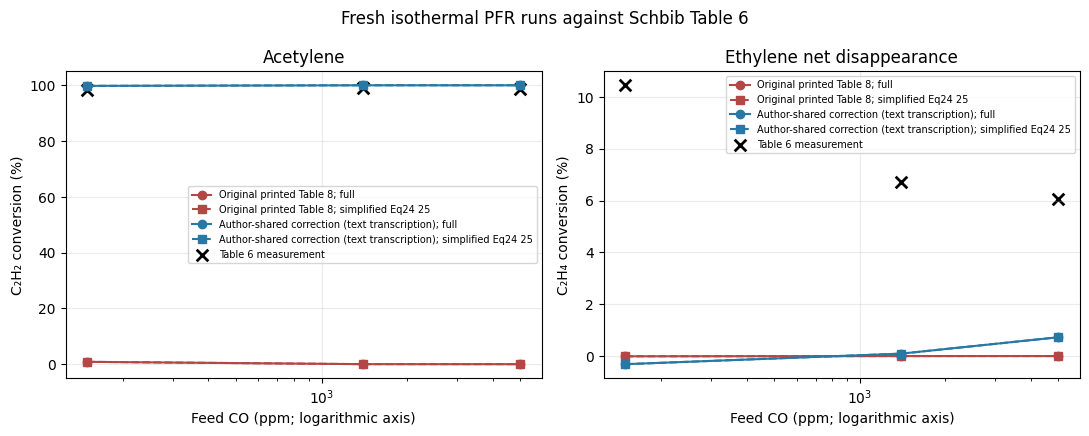

In [3]:
table6_results = []
sol_by_label = {}
for parameter_set in (TABLE8_PRINTED, AUTHOR_SHARED):
    for equation_name in ("full", "simplified_Eq24_25"):
        results, solutions = table6_run_rows(parameter_set, equation=equation_name)
        table6_results.append(results)
        sol_by_label[(parameter_set.label, equation_name)] = solutions
TABLE6_MODEL = pd.concat(table6_results, ignore_index=True)
display(TABLE6_MODEL.round(5))

full_results = TABLE6_MODEL[TABLE6_MODEL.equation.eq("full")]
for set_name, subset in full_results.groupby("set", sort=False):
    acetylene_gate = float(subset["C2H2 error (pp)"].abs().max())
    net_ethylene_gate = float(subset["C2H4 net error (pp)"].abs().max())
    extent_ethylene_gate = float(subset["C2H4 extent error (pp)"].abs().max())
    print(f"{set_name}: max |C2H2 error|={acetylene_gate:.3f} pp; max |C2H4 net error|={net_ethylene_gate:.3f} pp; max |C2H4 extent error|={extent_ethylene_gate:.3f} pp")
print("Acceptance: both reported species must be within 2 pp for every row. The all-species Table 6 gate is not passed if either species exceeds the limit.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
colors = {"Original printed Table 8": "#b24745", "Author-shared correction (text transcription)": "#2878a5"}
markers = {"full": "o", "simplified_Eq24_25": "s"}
for set_name in colors:
    for eq_name in ("full", "simplified_Eq24_25"):
        subset = TABLE6_MODEL[(TABLE6_MODEL["set"] == set_name) & (TABLE6_MODEL.equation == eq_name)]
        axes[0].plot(subset["CO (ppm)"], subset["C2H2 model (%)"], marker=markers[eq_name],
                     color=colors[set_name], linestyle="-" if eq_name == "full" else "--",
                     label=f"{set_name}; {eq_name.replace('_',' ')}")
        axes[1].plot(subset["CO (ppm)"], subset["C2H4 model net (%)"], marker=markers[eq_name],
                     color=colors[set_name], linestyle="-" if eq_name == "full" else "--",
                     label=f"{set_name}; {eq_name.replace('_',' ')}")
axes[0].scatter(TABLE6.CO_ppm, TABLE6.X_A_exp_pct, marker="x", s=70, linewidths=2,
                color="black", label="Table 6 measurement")
axes[1].scatter(TABLE6.CO_ppm, TABLE6.X_E_exp_pct, marker="x", s=70, linewidths=2,
                color="black", label="Table 6 measurement")
for ax, title, ylabel in zip(axes, ("Acetylene", "Ethylene net disappearance"), ("C₂H₂ conversion (%)", "C₂H₄ conversion (%)")):
    ax.set_xscale("log")
    ax.set_xlabel("Feed CO (ppm; logarithmic axis)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7)
fig.suptitle("Fresh isothermal PFR runs against Schbib Table 6")
fig.tight_layout()
plt.show()


### Table 6 reading

The original printed parameter set repeats the historical acetylene failure. The author-shared text set predicts acetylene within the provisional 2-point gate in all three cases. It does **not** reproduce ethylene: the model gives net ethylene formation or only slight net loss, while Table 6 reports 6.08–10.45% disappearance. The reaction-2 extent diagnostic is also below the measurements, so the discrepancy is not removed by the conversion-definition ambiguity. The Table 6 gate is **BLOCKED**.

At 16 atm and the same local state, both reactions share (D^{-3}), so (r_E/r_A=(k_E C_E)/(k_A C_A)) for positive (C_A). The shared CO term cancels in that local ratio. CO can still change integrated selectivity indirectly by changing the axial state and, under a thermal closure, the temperature history. The algebra alone does not establish selective CO inhibition.


## Controlled diagnostic sensitivities

Each row below begins with the original printed full-law model and replaces only the named parameter group with the author-shared transcription. These rows are diagnostics and are **not** additional physically consistent source models. The last row is the complete author-shared set, including its different kgcat rate basis. The source-consistent original and author-shared sets remain the comparison above.


,diagnostic,C2H2 predicted (%),C2H2 error (pp),C2H4 net predicted (%),C2H4 net error (pp),C2H4 reaction-2 extent (%),mass basis
0,Original printed full set,0.00986,-98.98014,-0.00011,-6.70011,0.00001,gcat
1,Diagnostic: only K_H logA corrected,0.01159,-98.97841,-0.00012,-6.70012,0.00001,gcat
2,Diagnostic: only K_CO logA corrected,45.88439,-53.10561,-0.47097,-7.17097,0.07143,gcat
3,Diagnostic: only K_E/K_Et/K_A logA corrected,0.00987,-98.98013,-0.00011,-6.70011,0.00001,gcat
4,"Diagnostic: original adsorption, kg rate basis",0.00001,-98.98999,-0.00000,-6.70000,0.00000,kgcat
5,Diagnostic: all five adsorption entries correc...,100.00000,1.01000,47.87452,41.17452,49.05660,gcat
6,Author-shared complete set,99.99824,1.00824,0.09353,-6.60647,1.27559,kgcat


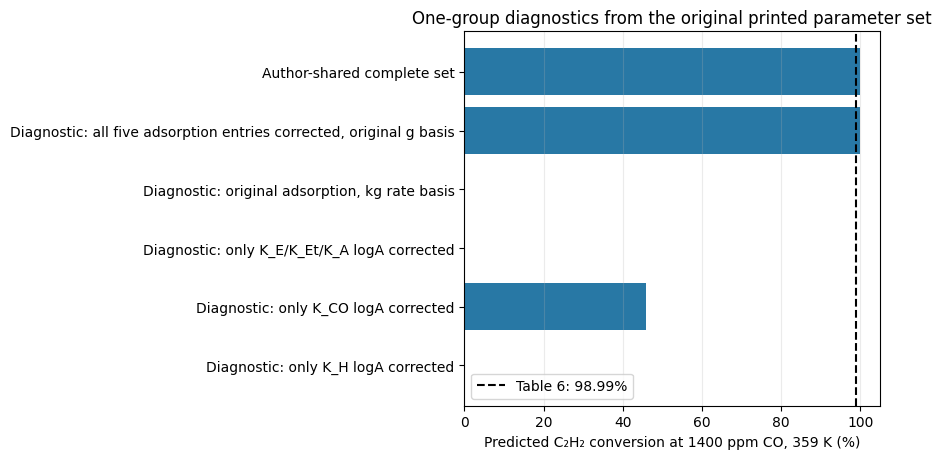

log10 factor K_CO correction at fixed E,T: 2754.2x lower pre-exponential
log10 factor K_H correction at fixed E,T: 1000.0x lower pre-exponential
The coupled full correction also changes three hydrocarbon adsorption constants and changes kA/kE from a gcat to kgcat rate basis.


In [4]:
original_to_corrected = {
    "Original printed full set": TABLE8_PRINTED,
    "Diagnostic: only K_H logA corrected": replace(TABLE8_PRINTED, log_KH=AUTHOR_SHARED.log_KH),
    "Diagnostic: only K_CO logA corrected": replace(TABLE8_PRINTED, log_KCO=AUTHOR_SHARED.log_KCO),
    "Diagnostic: only K_E/K_Et/K_A logA corrected": replace(
        TABLE8_PRINTED, log_KE=AUTHOR_SHARED.log_KE, log_KEt=AUTHOR_SHARED.log_KEt, log_KA=AUTHOR_SHARED.log_KA
    ),
    "Diagnostic: original adsorption, kg rate basis": replace(TABLE8_PRINTED, rate_mass_basis="kgcat"),
    "Diagnostic: all five adsorption entries corrected, original g basis": replace(
        TABLE8_PRINTED, log_KH=AUTHOR_SHARED.log_KH, log_KCO=AUTHOR_SHARED.log_KCO,
        log_KE=AUTHOR_SHARED.log_KE, log_KEt=AUTHOR_SHARED.log_KEt, log_KA=AUTHOR_SHARED.log_KA
    ),
    "Author-shared complete set": AUTHOR_SHARED,
}

sens_rows = []
for label, p in original_to_corrected.items():
    one, _ = table6_run_rows(p, equation="full")
    row = one.loc[one["CO (ppm)"].eq(1400.0)].iloc[0]
    sens_rows.append({
        "diagnostic": label,
        "C2H2 predicted (%)": row["C2H2 model (%)"],
        "C2H2 error (pp)": row["C2H2 error (pp)"],
        "C2H4 net predicted (%)": row["C2H4 model net (%)"],
        "C2H4 net error (pp)": row["C2H4 net error (pp)"],
        "C2H4 reaction-2 extent (%)": row["C2H4 reaction-2 extent (%)"],
        "mass basis": p.rate_mass_basis,
    })
SENSITIVITY = pd.DataFrame(sens_rows)
display(SENSITIVITY.round(5))

fig, ax = plt.subplots(figsize=(9, 4.7))
view = SENSITIVITY.iloc[1:].copy()
ax.barh(view["diagnostic"], view["C2H2 predicted (%)"], color="#2878a5")
ax.axvline(TABLE6.loc[1, "X_A_exp_pct"], color="black", linestyle="--", label="Table 6: 98.99%")
ax.set(xlabel="Predicted C₂H₂ conversion at 1400 ppm CO, 359 K (%)",
       title="One-group diagnostics from the original printed parameter set")
ax.grid(axis="x", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

print(f"log10 factor K_CO correction at fixed E,T: {10.0 ** (TABLE8_PRINTED.log_KCO - AUTHOR_SHARED.log_KCO):.1f}x lower pre-exponential")
print(f"log10 factor K_H correction at fixed E,T: {10.0 ** (TABLE8_PRINTED.log_KH - AUTHOR_SHARED.log_KH):.1f}x lower pre-exponential")
print("The coupled full correction also changes three hydrocarbon adsorption constants and changes kA/kE from a gcat to kgcat rate basis.")


### Sensitivity interpretation

At 1400 ppm, changing only (K_{CO})'s pre-exponential moves predicted acetylene conversion from about 0.01% to about 46%; changing only (K_H) has little effect because the original CO term dominates this denominator. The complete author-shared set is coupled: it lowers both H₂ and CO adsorption pre-exponentials, changes the other adsorption terms, and leaves kA/kE with the same log numbers while expressing the rates per kg instead of per g. The denominator is cubed, so these effects do not add linearly. This supports a strong role for the KCO entry in the historical acetylene failure, but it does not isolate a unique cause for all Table 6 errors.

The corrected hydrocarbon terms barely change the model because they are negligible at these conditions, in agreement with the paper's statement preceding Eqs. 24–25. The net/reaction-specific ethylene comparison remains outside tolerance for every source-consistent set.


## Figure 1–4 comparisons

The article's figures are retained as source evidence, not reconstructed raw datasets. Figure 1 has no numerical table of plotted points. Figure 2 does not report space velocity in its caption. Figures 3 and 4 specify model III and show experimental markers, but their captions omit catalyst mass/space velocity and packed-bed void/length mapping. Model III also solves gas/solid temperature and concentration differences; the local catalyst pellet diameter and complete transfer/boundary inputs needed for a faithful rerun are not established by Tables 3, 4, 6 or 8. The reported 1000 Å property is mean pore diameter, not pellet diameter.

The comparisons below use reported text/narrative points where available and label borrowed assumptions. Figure pass status is separate from the Table 6 gate.


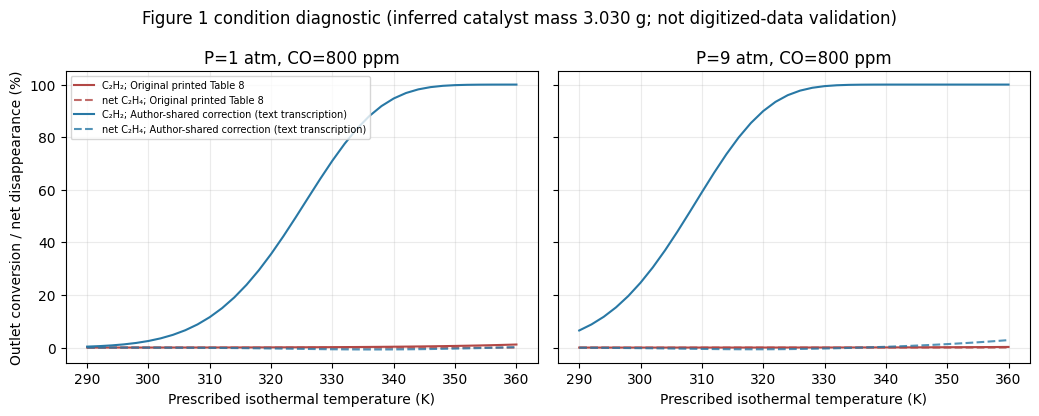

Figure 2 reported inlet: Table 3 feed, T0=325 K, P=16.3 atm, CO=1400 ppm
Corrected-set inlet rates (kmol kgcat-1 s-1): rA=4.6569e-07, rE=6.6625e-08; D=14.2515


,figure,T0 (K),set,X_A model isothermal (%),source text/figure approximate X_A (%),error (pp),temperature rise in this closure (K),borrowed condition
0,3,325.0,Original printed Table 8,0.0009,70.7,-70.6991,0.0,1 g from Table 6 SV; not stated in Figure caption
1,3,325.0,Author-shared correction (text transcription),70.1000,70.7,-0.6000,0.0,1 g from Table 6 SV; not stated in Figure caption
2,4,345.0,Original printed Table 8,0.0039,98.0,-97.9961,0.0,1 g from Table 6 SV; not stated in Figure caption
3,4,345.0,Author-shared correction (text transcription),99.1741,98.0,1.1741,0.0,1 g from Table 6 SV; not stated in Figure caption


In [5]:
# Figure 1: the caption gives SV=33 cm3(STP)/(gcat min); Table 3 gives 100 cm3(STP)/min.
# Thus 100/33 g is the explicit catalyst-mass inference used only for this diagnostic.
fig1_mass_g = 100.0 / 33.0
fig1_rows = []
fig1_sweep = np.linspace(290.0, 360.0, 36)
for pressure_atm in (1.0, 9.0):
    for temp in fig1_sweep:
        for p in (TABLE8_PRINTED, AUTHOR_SHARED):
            sol = run_pfr(800.0, float(temp), pressure_atm, 100.0, fig1_mass_g, p, equation="full")
            fig1_rows.append({"P_atm": pressure_atm, "T_K": temp, "set": p.label,
                              "X_A_pct": sol.X_A_pct, "X_E_net_pct": sol.X_E_net_pct})
FIG1_DIAGNOSTIC = pd.DataFrame(fig1_rows)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
for ax, pressure_atm in zip(axes, (1.0, 9.0)):
    for p, color in ((TABLE8_PRINTED, "#b24745"), (AUTHOR_SHARED, "#2878a5")):
        sub = FIG1_DIAGNOSTIC[(FIG1_DIAGNOSTIC.P_atm.eq(pressure_atm)) & (FIG1_DIAGNOSTIC["set"].eq(p.label))]
        ax.plot(sub.T_K, sub.X_A_pct, color=color, label=f"C₂H₂; {p.label}")
        ax.plot(sub.T_K, sub.X_E_net_pct, color=color, linestyle="--", alpha=0.8, label=f"net C₂H₄; {p.label}")
    ax.set(title=f"P={pressure_atm:g} atm, CO=800 ppm", xlabel="Prescribed isothermal temperature (K)")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Outlet conversion / net disappearance (%)")
axes[0].legend(fontsize=7)
fig.suptitle(f"Figure 1 condition diagnostic (inferred catalyst mass {fig1_mass_g:.3f} g; not digitized-data validation)")
fig.tight_layout()
plt.show()

# Figure 2: calculate the corrected-set initial rates at the exact reported inlet conditions.
fig2_flow = inlet_flow_kmol_s(100.0, 1400.0)
fig2_rates, fig2_denom, fig2_C = calculate_rates(fig2_flow, 325.0, 16.3, AUTHOR_SHARED, equation="full")
print("Figure 2 reported inlet: Table 3 feed, T0=325 K, P=16.3 atm, CO=1400 ppm")
print(f"Corrected-set inlet rates (kmol kgcat-1 s-1): rA={fig2_rates[0]:.6g}, rE={fig2_rates[1]:.6g}; D={fig2_denom:.6g}")

# Figures 3 and 4: caption omits SV; borrow Table 6's 100 cm3(STP)/(gcat min) for a stated diagnostic.
fig_profile_rows = []
for number, T0, source_XA in ((3, 325.0, 70.7), (4, 345.0, 98.0)):
    for p in (TABLE8_PRINTED, AUTHOR_SHARED):
        sol = run_pfr(1400.0, T0, 16.3, 100.0, 1.0, p, equation="full", thermal_mode="isothermal")
        fig_profile_rows.append({
            "figure": number, "T0 (K)": T0, "set": p.label,
            "X_A model isothermal (%)": sol.X_A_pct,
            "source text/figure approximate X_A (%)": source_XA,
            "error (pp)": sol.X_A_pct - source_XA,
            "temperature rise in this closure (K)": sol.y[-1, -1] - T0,
            "borrowed condition": "1 g from Table 6 SV; not stated in Figure caption",
        })
FIG_PROFILE = pd.DataFrame(fig_profile_rows)
display(FIG_PROFILE.round(4))


### Figure comparison gates

- **Figure 1 — BLOCKED quantitatively.** The corrected-set diagnostic uses the caption's (SV=33) with the Table 3 flow to infer 3.03 g and assumes isothermal conditions. The source supplies plotted curves, not tabulated points; no pointwise dataset was digitized. The previous Figure 1 PNG is visibly on a sub-1.2% scale and is not a reproduction of the paper's roughly 70–100% acetylene conversion panel.
- **Figure 2 — PARTIAL scale check; full reproduction BLOCKED.** At the exact caption inlet condition, the corrected-set inlet rates are on the order of (10^{-7}) kmol kgcat⁻¹ s⁻¹, consistent with the plotted vertical scale. The caption omits residence time/space velocity, and the plotted rates trace an adiabatic reactor path, so the complete curve is not independently reproduced.
- **Figure 3 — partial acetylene outlet check; profile BLOCKED.** The corrected-set isothermal diagnostic gives approximately 70.10% C₂H₂ at the borrowed Table 6 space velocity, versus 70.7% stated in the paper. It cannot reproduce the paper's roughly 1.5 K hot spot because this diagnostic is isothermal.
- **Figure 4 — partial acetylene outlet check; profile BLOCKED.** The same borrowed closure gives approximately 99.17% C₂H₂ versus “close to 98%” in the paper text. It predicts zero temperature rise, whereas the article reports a hot spot exceeding 3 K. Model III transfer/heat-boundary behavior remains unverified.

These close Figure 3/4 conversion values are useful checks on the correction set, but do not override the failed ethylene Table 6 gate or validate the missing model III fields.


## Heat-closure sensitivity: historical assumption only

Table 6 temperatures are treated as prescribed isothermal values for the primary comparison because the experiments used a diethylene-glycol bath and report catalyst-contact thermocouple temperature. The article's laboratory model III includes external heat and mass transfer. To expose the effect of a radically different closure, an adiabatic calculation below reuses only the old notebook's assumed reaction heats and NASA7 ideal-gas Cp values. The old notebook attributed the heats (-172 and -136 kJ/mol) to a prior GOAL, but they are not in the current mission specification and are not transcribed from Schbib Tables 3, 4, 6 or 8. Its NASA7 coefficients were attributed to GRI-Mech 3.0 `gri30.yaml` (https://github.com/Cantera/cantera/blob/main/data/gri30.yaml); they were not independently re-audited here. These energy inputs are diagnostic inputs, not verified Schbib data.


,set,CO (ppm),T (K),C2H2 model (%),C2H4 model net (%),T outlet (K)
0,Original printed Table 8,150.0,341.0,0.8460,-0.0088,341.1832
1,Original printed Table 8,1400.0,359.0,0.0099,-0.0001,359.0020
2,Original printed Table 8,5000.0,393.0,0.0018,-0.0000,393.0003
3,Author-shared correction (text transcription),150.0,341.0,100.0000,7.9446,468.2549
4,Author-shared correction (text transcription),1400.0,359.0,100.0000,47.8745,836.3043
5,Author-shared correction (text transcription),5000.0,393.0,100.0000,47.8745,855.8249


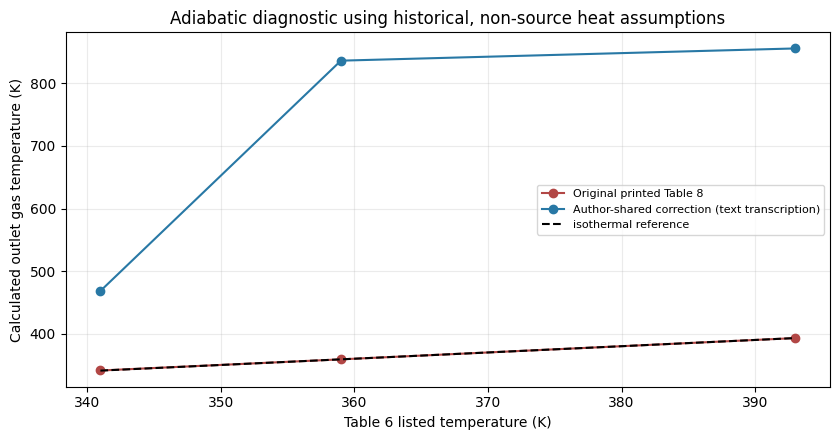

In [6]:
thermal_rows = []
for p in (TABLE8_PRINTED, AUTHOR_SHARED):
    result, _ = table6_run_rows(p, equation="full", thermal_mode="historical_adiabatic_assumption")
    thermal_rows.append(result)
THERMAL_DIAGNOSTIC = pd.concat(thermal_rows, ignore_index=True)
display(THERMAL_DIAGNOSTIC[["set", "CO (ppm)", "T (K)", "C2H2 model (%)", "C2H4 model net (%)", "T outlet (K)"]].round(4))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for p, color in ((TABLE8_PRINTED, "#b24745"), (AUTHOR_SHARED, "#2878a5")):
    subset = THERMAL_DIAGNOSTIC[THERMAL_DIAGNOSTIC["set"].eq(p.label)]
    ax.plot(subset["T (K)"], subset["T outlet (K)"], marker="o", color=color, label=p.label)
ax.plot(TABLE6.T_K, TABLE6.T_K, color="black", linestyle="--", label="isothermal reference")
ax.set(xlabel="Table 6 listed temperature (K)", ylabel="Calculated outlet gas temperature (K)",
       title="Adiabatic diagnostic using historical, non-source heat assumptions")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


### Heat-closure interpretation

For the original printed set, this historical adiabatic closure changes the Table 6 conversion only slightly because the predicted reaction rates are tiny. For the author-shared set, the same adiabatic closure drives the calculation far above the reported bath temperatures; the isothermal and adiabatic Table 6 results therefore answer different physical questions. These high adiabatic temperatures are a warning that a bath/film energy model is needed, not a prediction of the actual laboratory reactor. Missing wall-temperature profiles, bed loading/void data, pellet diameter, and verified transfer inputs prevent that model III reconstruction here.


## Internal verification checks

These checks validate implementation consistency, not the published model's physical correctness. The acceptance tolerances are: element-flow drift (<10^{-8}) relative; exact mol↔kmol trajectory conversion difference (<10^{-8}) relative; solver refinement change (<0.01) percentage point in either outlet conversion and (<0.01) K; all reported denominators finite and positive.


In [7]:
# Stoichiometry and atom conservation.
assert np.allclose(ELEMENTS @ NU, 0.0, atol=1e-14)

# Exact concentration/rate-unit conversion: compare one complete trajectory both ways.
unit_kmol = run_pfr(1400.0, 359.0, 16.0, 100.0, 1.0, AUTHOR_SHARED,
                    equation="full", concentration_basis="kmol")
unit_mol = run_pfr(1400.0, 359.0, 16.0, 100.0, 1.0, AUTHOR_SHARED,
                   equation="full", concentration_basis="mol")
unit_delta_xA = abs(unit_kmol.X_A_pct - unit_mol.X_A_pct)
unit_delta_xE = abs(unit_kmol.X_E_net_pct - unit_mol.X_E_net_pct)
assert unit_delta_xA < 1e-8 and unit_delta_xE < 1e-8

# Check all Table 6 source-model solution states for finite/nonnegative flows and element conservation.
state_checks = []
for (set_name, eq_name), solutions in sol_by_label.items():
    for case_index, sol in enumerate(solutions):
        flow_states = sol.flow_kmol_s
        element_flows = ELEMENTS @ flow_states
        relative_element_drift = np.max(np.abs(element_flows - element_flows[:, [0]])) / np.max(np.abs(element_flows[:, [0]]))
        minimum_flow = float(flow_states.min())
        denominator_min = np.inf
        for j in range(flow_states.shape[1]):
            rates, denominator, _ = calculate_rates(flow_states[:, j], TABLE6.iloc[case_index].T_K,
                                                    16.0, TABLE8_PRINTED if set_name == TABLE8_PRINTED.label else AUTHOR_SHARED,
                                                    eq_name)
            denominator_min = min(denominator_min, denominator)
        state_checks.append({"set": set_name, "equation": eq_name, "case": case_index + 1,
                             "minimum flow (kmol/s)": minimum_flow,
                             "minimum denominator": denominator_min,
                             "relative element-flow drift": relative_element_drift})
STATE_CHECKS = pd.DataFrame(state_checks)
display(STATE_CHECKS.to_string(index=False))
assert np.isfinite(STATE_CHECKS[["minimum flow (kmol/s)", "minimum denominator", "relative element-flow drift"]].to_numpy()).all()
assert (STATE_CHECKS["minimum denominator"] > 0.0).all()
assert (STATE_CHECKS["minimum flow (kmol/s)"] >= -1e-16).all()
assert (STATE_CHECKS["relative element-flow drift"] < 1e-8).all()

# Solver refinement on the corrected full-law 1400 ppm case.
coarse = run_pfr(1400.0, 359.0, 16.0, 100.0, 1.0, AUTHOR_SHARED,
                 equation="full", rtol=1e-7, atol=1e-16, n_points=61)
fine = run_pfr(1400.0, 359.0, 16.0, 100.0, 1.0, AUTHOR_SHARED,
               equation="full", rtol=1e-11, atol=1e-21, n_points=361)
refinement_xA_pp = abs(coarse.X_A_pct - fine.X_A_pct)
refinement_xE_pp = abs(coarse.X_E_net_pct - fine.X_E_net_pct)
refinement_T_K = abs(coarse.y[-1, -1] - fine.y[-1, -1])
print(f"Unit-basis conversion deltas: C2H2={unit_delta_xA:.3g} pp; C2H4 net={unit_delta_xE:.3g} pp")
print(f"Solver refinement: C2H2={refinement_xA_pp:.3g} pp; C2H4 net={refinement_xE_pp:.3g} pp; Tout={refinement_T_K:.3g} K")
assert refinement_xA_pp < 0.01 and refinement_xE_pp < 0.01 and refinement_T_K < 0.01

# Logarithm and Arrhenius sanity: A is 10**logA, and positive E gives increasing k(T).
A_kA = 10.0 ** AUTHOR_SHARED.log_kA
k_325 = arrhenius_from_logs([AUTHOR_SHARED.log_kA], [AUTHOR_SHARED.E_kA_kcal_mol], 325.0)[0]
k_359 = arrhenius_from_logs([AUTHOR_SHARED.log_kA], [AUTHOR_SHARED.E_kA_kcal_mol], 359.0)[0]
assert np.isclose(A_kA, 10.0 ** 31.1)
assert k_359 > k_325
print(f"Arrhenius check: A_kA=10^31.1={A_kA:.4g}; kA(325 K)={k_325:.4g}, kA(359 K)={k_359:.4g} in the canonical kg/kmol basis")
print("PASS: element balance, positivity, concentration-unit invariance, solver refinement, and Arrhenius checks.")


'                                          set           equation  case  minimum flow (kmol/s)  minimum denominator  relative element-flow drift\n                     Original printed Table 8               full     1           1.115376e-11          2145.081334                 3.488673e-16\n                     Original printed Table 8               full     2           1.041017e-10         28054.827285                 1.746520e-16\n                     Original printed Table 8               full     3           3.717919e-10        294593.266323                 8.764195e-16\n                     Original printed Table 8 simplified_Eq24_25     1           1.115376e-11          2144.477819                 3.488673e-16\n                     Original printed Table 8 simplified_Eq24_25     2           1.041017e-10         28054.254577                 1.746520e-16\n                     Original printed Table 8 simplified_Eq24_25     3           3.717919e-10        294592.744793               

Unit-basis conversion deltas: C2H2=3.19e-11 pp; C2H4 net=1.62e-13 pp
Solver refinement: C2H2=1.1e-10 pp; C2H4 net=1.52e-12 pp; Tout=0 K
Arrhenius check: A_kA=10^31.1=1.259e+31; kA(325 K)=3.14, kA(359 K)=2485 in the canonical kg/kmol basis
PASS: element balance, positivity, concentration-unit invariance, solver refinement, and Arrhenius checks.


## Figure and scientific verification gates

| Gate | Receipt | Status |
|---|---|---|
| Original article Table 3/4/6/8 transcription | Rendered PDF pages 4, 6, 7, 8 checked against printed pages 1499, 1501–1503 | PASS |
| Author-shared correction source | Table read from ResearchGate extracted full-text; linked PDF fetch is 404; no ACS erratum confirmed | BLOCKED for visual/source-status verification; diagnostic set retained |
| Source parameter sets | Printed Table 8 and author-shared text set kept distinct; correction sensitivities separately marked | PASS for implementation separation |
| Internal numerical checks | Conservation, positive denominators, unit invariance, solver refinement | PASS if assertions above complete |
| Table 6 acetylene conversion | Corrected set within 2 pp; original set fails by up to about 99 pp | Partial; corrected set passes this species only |
| Table 6 ethylene conversion | Net disappearance and reaction-2 extent both exceed 2 pp error for the correction set | BLOCKED |
| Figure 1 | Source plot has no tabulated pointwise values; current curve is diagnostic only | BLOCKED quantitatively |
| Figure 2 | Corrected inlet-rate scale check only; caption omits space velocity for full adiabatic path | BLOCKED for full curve |
| Figures 3–4 | Acetylene conversion check near source text values; model III heat/transfer profiles are not reproduced | PARTIAL / BLOCKED for full figures |

## What the calculation does not establish

- It does not prove the author-shared text is an official correction or visually verified source artifact.
- It does not resolve why Table 6 ethylene conversion remains much higher than either model's reaction-2 consumption. The paper itself notes large experimental error in ethylene conversion; no uncertainty bars for Table 6 are given.
- It does not determine whether the Table 6 temperature is a true isothermal bed temperature everywhere or an axial thermocouple reading representative of the catalyst bed.
- It does not reproduce the glycol-bath/model-III wall, gas-film, or particle-surface conditions.
- It does not establish parameter transfer from commercial Pd/α-Al₂O₃ to PdAg.


In [8]:
print("Reproducibility receipt")
print(f"Execution command: jupyter execute --inplace schbib_1996_steady_state.ipynb (working directory notebooks/benchmarks)")
print(f"Kernel executable: {sys.executable}")
print(f"Runtime: {platform.platform()} | Python {sys.version.split()[0]}")
print(f"Dependencies: NumPy {np.__version__}, SciPy {scipy.__version__}, pandas {pd.__version__}, Matplotlib {plt.matplotlib.__version__}")
print("Selected environment: installed Codex Python 3.12.14 runtime; Conda is absent. No packages installed or dependency files changed.")
print("Solver: scipy.integrate.solve_ivp(method='Radau'); default rtol=1e-10, atol=1e-19, max_step=mass/80.")
print("Runtime check: compatible Python and required packages executed this notebook; numerical work is not blocked by missing Conda.")
print("Source revision before audit edits: 155a1e6ed00e92ed6f18535ae90708bf22c98584; final artifact commit is recorded in the audit report.")


Reproducibility receipt
Execution command: jupyter execute --inplace schbib_1996_steady_state.ipynb (working directory notebooks/benchmarks)
Kernel executable: /opt/codex/runtimes/codex-primary-runtime/dependencies/python/bin/python
Runtime: Linux-6.18.55-x86_64-with-glibc2.41 | Python 3.12.14
Dependencies: NumPy 2.3.5, SciPy 1.17.0, pandas 2.2.3, Matplotlib 3.10.8
Selected environment: installed Codex Python 3.12.14 runtime; Conda is absent. No packages installed or dependency files changed.
Solver: scipy.integrate.solve_ivp(method='Radau'); default rtol=1e-10, atol=1e-19, max_step=mass/80.
Runtime check: compatible Python and required packages executed this notebook; numerical work is not blocked by missing Conda.
Source revision before audit edits: 155a1e6ed00e92ed6f18535ae90708bf22c98584; final artifact commit is recorded in the audit report.
